The imports and data:

In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Assigning names to the sets
train = pd.read_csv('/content/drive/MyDrive/Kaggle/churn_train.csv')
test = pd.read_csv('/content/drive/MyDrive/Kaggle/churn_test.csv')
accounts = pd.read_csv('/content/drive/MyDrive/Kaggle/accounts.csv')
demographics = pd.read_csv('/content/drive/MyDrive/Kaggle/demographics.csv')
services = pd.read_csv('/content/drive/MyDrive/Kaggle/services.csv')
submission = pd.read_csv('/content/drive/MyDrive/Kaggle/sample_submission.csv')

In [ ]:
# Looking at the data sets
display(train.head())
display(test.head())
display(accounts.head())
display(demographics.head())
display(services.head())
display(submission.head())

,CustomerNo,Churn
0,1201,0
1,1202,0
2,1205,1
3,1206,0
4,1207,0


,CustomerNo
0,1203
1,1204
2,1208
3,1220
4,1221


,CustomerNo,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
0,1201,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check
1,1202,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check
2,1203,399.75,5-1-2012,5217.00,10-Jan-11,Yes,Month-to-month,Bank transfer (automatic)
3,1204,324.75,5-1-2012,22757.50,6-Apr-06,No,One year,Bank transfer (automatic)
4,1205,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check


,CustomerNo,Country,State,Retired,HasPartner,HasDependents,Education,Gender
0,1201,India,Maharashtra,0,2,2,Masters,Male
1,1202,India,Maharashtra,0,2,2,ProfessionalQalification,Male
2,1203,India,Maharashtra,0,2,2,ProfessionalQalification,Male
3,1204,India,Maharashtra,0,2,1,ProfessionalQalification,Male
4,1205,India,Maharashtra,0,2,2,ProfessionalQalification,Female


,CustomerNo,TypeOfService,SeviceDetails
0,1201,DeviceProtection,Yes
1,1201,HasPhoneService,1
2,1201,InternetServiceCategory,Fiber optic
3,1201,MultipleLines,No
4,1201,OnlineBackup,No


,CustomerNo,Churn
0,1203,0
1,1204,0
2,1208,0
3,1220,0
4,1221,0


cleaning the data

In [ ]:
# Converting services from long to wide format
services_wide = services.pivot_table(
    index='CustomerNo',
    columns='TypeOfService',
    values='SeviceDetails',
    aggfunc='first'
).reset_index()

# Viewing the new dataset
display(services_wide.head())


TypeOfService,CustomerNo,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,TechnicalSupport
0,1201,Yes,1,Fiber optic,No,No,No,Yes,Yes,No
1,1202,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
2,1203,No,1,Fiber optic,No,No,No,Yes,No,No
3,1204,No,1,DSL,Yes,Yes,Yes,No,No,Yes
4,1205,No,1,Fiber optic,Yes,No,No,No,No,No


In [ ]:
# Merging data to make it easier to work on
train_full = train.merge(accounts, on='CustomerNo', how='left')

train_full = train_full.merge( demographics, on='CustomerNo', how='left')

train_full = train_full.merge(services_wide, on='CustomerNo', how='left')

In [ ]:
# Merging training data
test_full = test.merge(accounts, on='CustomerNo', how='left')

test_full = test_full.merge(
    demographics, on='CustomerNo', how='left'
)

test_full = test_full.merge(
    services_wide, on='CustomerNo', how='left'
)


In [ ]:
#checking that everything combined well
print("Training data:", train_full.shape)
print("Testing data:", test_full.shape)

display(train_full.head())


Training data: (4238, 25)
Testing data: (1060, 24)


,CustomerNo,Churn,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod,Country,...,Gender,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,TechnicalSupport
0,1201,0,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check,India,...,Male,Yes,1,Fiber optic,No,No,No,Yes,Yes,No
1,1202,0,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check,India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
2,1205,1,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check,India,...,Female,No,1,Fiber optic,Yes,No,No,No,No,No
3,1206,0,99.50,5-1-2012,6775.50,7-Mar-06,Yes,Two year,Credit card (automatic),India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
4,1207,0,91.25,5-1-2012,2673.50,17-Sep-09,No,One year,Credit card (automatic),India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service


In [ ]:
# Getting a count customers in each churn category
print(train_full['Churn'].value_counts())

# Calculating percentages
print(train_full['Churn'].value_counts(normalize=True) * 100)

Churn
0    3189
1    1049
Name: count, dtype: int64
Churn
0    75.247758
1    24.752242
Name: proportion, dtype: float64


In [ ]:
# Checking for missing values
print("Missing values:")
print(train_full.isnull().sum().sort_values(ascending=False))

# Checking data types
train_full.info()

Missing values:
Education                  9
TotalCharges               8
ContractType               3
Gender                     2
CustomerNo                 0
DOC                        0
DOE                        0
BaseCharges                0
Churn                      0
PaymentMethod              0
ElectronicBilling          0
Country                    0
State                      0
HasPartner                 0
Retired                    0
HasDependents              0
DeviceProtection           0
HasPhoneService            0
InternetServiceCategory    0
MultipleLines              0
OnlineBackup               0
OnlineSecurity             0
StreamingMovies            0
StreamingTelevision        0
TechnicalSupport           0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   CustomerNo               4

In [ ]:
# Fixing missing numerical values with the median value
train_full['TotalCharges'] = train_full['TotalCharges'].fillna(
    train_full['TotalCharges'].median()
)

# Fill missing categorical values with the most common category
for column in ['Education', 'ContractType', 'Gender']:

    train_full[column] = train_full[column].fillna(
        train_full[column].mode()[0]
    )

# Checking missing missing values again to make sure i got everything
print(train_full.isnull().sum().sum())


0


In [ ]:
#looking at what the data looks like about how many churn
print(train_full['Churn'].value_counts())

print("\nChurn percentages:")
print(train_full['Churn'].value_counts(normalize=True) * 100)

Churn
0    3189
1    1049
Name: count, dtype: int64

Churn percentages:
Churn
0    75.247758
1    24.752242
Name: proportion, dtype: float64


In [ ]:
#Seeing whats useful to keep
print("DOC unique values:")
print(train_full['DOC'].nunique())

print("\nDOE unique values:")
print(train_full['DOE'].nunique())

print("\nSample dates:")
display(train_full[['DOC', 'DOE', 'Churn']].head(10))

DOC unique values:
1

DOE unique values:
73

Sample dates:


,DOC,DOE,Churn
0,5-1-2012,10-Jan-11,0
1,5-1-2012,6-Dec-11,0
2,5-1-2012,6-Dec-11,1
3,5-1-2012,7-Mar-06,0
4,5-1-2012,17-Sep-09,0
5,5-1-2012,10-Jan-11,0
6,5-1-2012,23-Aug-08,0
7,5-1-2012,11-Mar-11,0
8,5-1-2012,12-Oct-10,0
9,5-1-2012,7-Oct-11,1


In [ ]:
# Convert "Date of enrolment" into datetime format
train_full['DOE'] = pd.to_datetime(
    train_full['DOE'],
    format='%d-%b-%y',
    errors='coerce'
)

test_full['DOE'] = pd.to_datetime(
    test_full['DOE'],
    format='%d-%b-%y',
    errors='coerce'
)

# Set the common observation date
reference_date = pd.Timestamp('2012-05-01')

# Calculate customer tenure in days
train_full['TenureDays'] = (
    reference_date - train_full['DOE']
).dt.days

test_full['TenureDays'] = (
    reference_date - test_full['DOE']
).dt.days

# Remove original date columns
train_full = train_full.drop(columns=['DOC', 'DOE'])
test_full = test_full.drop(columns=['DOC', 'DOE'])

# Check our new variable
display(train_full[['CustomerNo', 'TenureDays', 'Churn']].head(10))


,CustomerNo,TenureDays,Churn
0,1201,477,0
1,1202,147,0
2,1205,147,1
3,1206,2247,0
4,1207,957,0
5,1209,477,0
6,1210,1347,0
7,1211,417,0
8,1212,567,0
9,1213,207,1


In [ ]:
# Calculate average time stayed for each churn group
print(
    train_full.groupby('Churn')['TenureDays'].mean()
)

Churn
0    1274.836312
1     679.192564
Name: TenureDays, dtype: float64


In [ ]:
# Identifing numerical and categorical columns
numeric_cols = train_full.select_dtypes(
    include=['number']
).columns.drop(['CustomerNo', 'Churn'])

categorical_cols = train_full.select_dtypes(
    include=['object']
).columns

# Filling missing numerical values
for col in numeric_cols:
    test_full[col] = test_full[col].fillna(
        train_full[col].median()
    )

# Filling missing categorical values
for col in categorical_cols:
    test_full[col] = test_full[col].fillna(
        train_full[col].mode()[0]
    )


In [ ]:

# Remove Churn and CustomerNo from predictors
#CostomerNo doesn't matter to the predictions and removing churn to start my testing
X = train_full.drop(
    columns=['Churn', 'CustomerNo']
)

# Churn is our target
y = train_full['Churn']

# Prepare the Kaggle test data
X_test = test_full.drop(columns=['CustomerNo'])


In [ ]:
# Combine training and testing predictors
combined = pd.concat([X, X_test], axis=0)

# Convert categorical variables into numerical columns
combined_encoded = pd.get_dummies(combined, drop_first=True)

# Separate training and testing data again
X_encoded = combined_encoded.iloc[:len(X)]
X_test_encoded = combined_encoded.iloc[len(X):]

In [ ]:
# Splitting the training and validation sets
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


The Random Forest model:

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict churn on validation data
y_pred = rf_model.predict(X_val)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_val, y_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

# Evaluate probability predictions
y_prob = rf_model.predict_proba(X_val)[:, 1]

print("ROC-AUC:", roc_auc_score(y_val, y_prob))

Accuracy: 0.8160377358490566

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.93      0.88       638
           1       0.68      0.48      0.56       210

    accuracy                           0.82       848
   macro avg       0.76      0.70      0.72       848
weighted avg       0.80      0.82      0.80       848


Confusion Matrix:
[[592  46]
 [110 100]]
ROC-AUC: 0.8429541722645172


In [ ]:
#im intrested to see what heis tree looks like
first_tree = rf_model.estimators_[0]

print("Total tree depth:", first_tree.get_depth())
print("Total number of nodes:", first_tree.tree_.node_count)
print("Number of leaf nodes:", first_tree.get_n_leaves())


Total tree depth: 21
Total number of nodes: 1307
Number of leaf nodes: 654


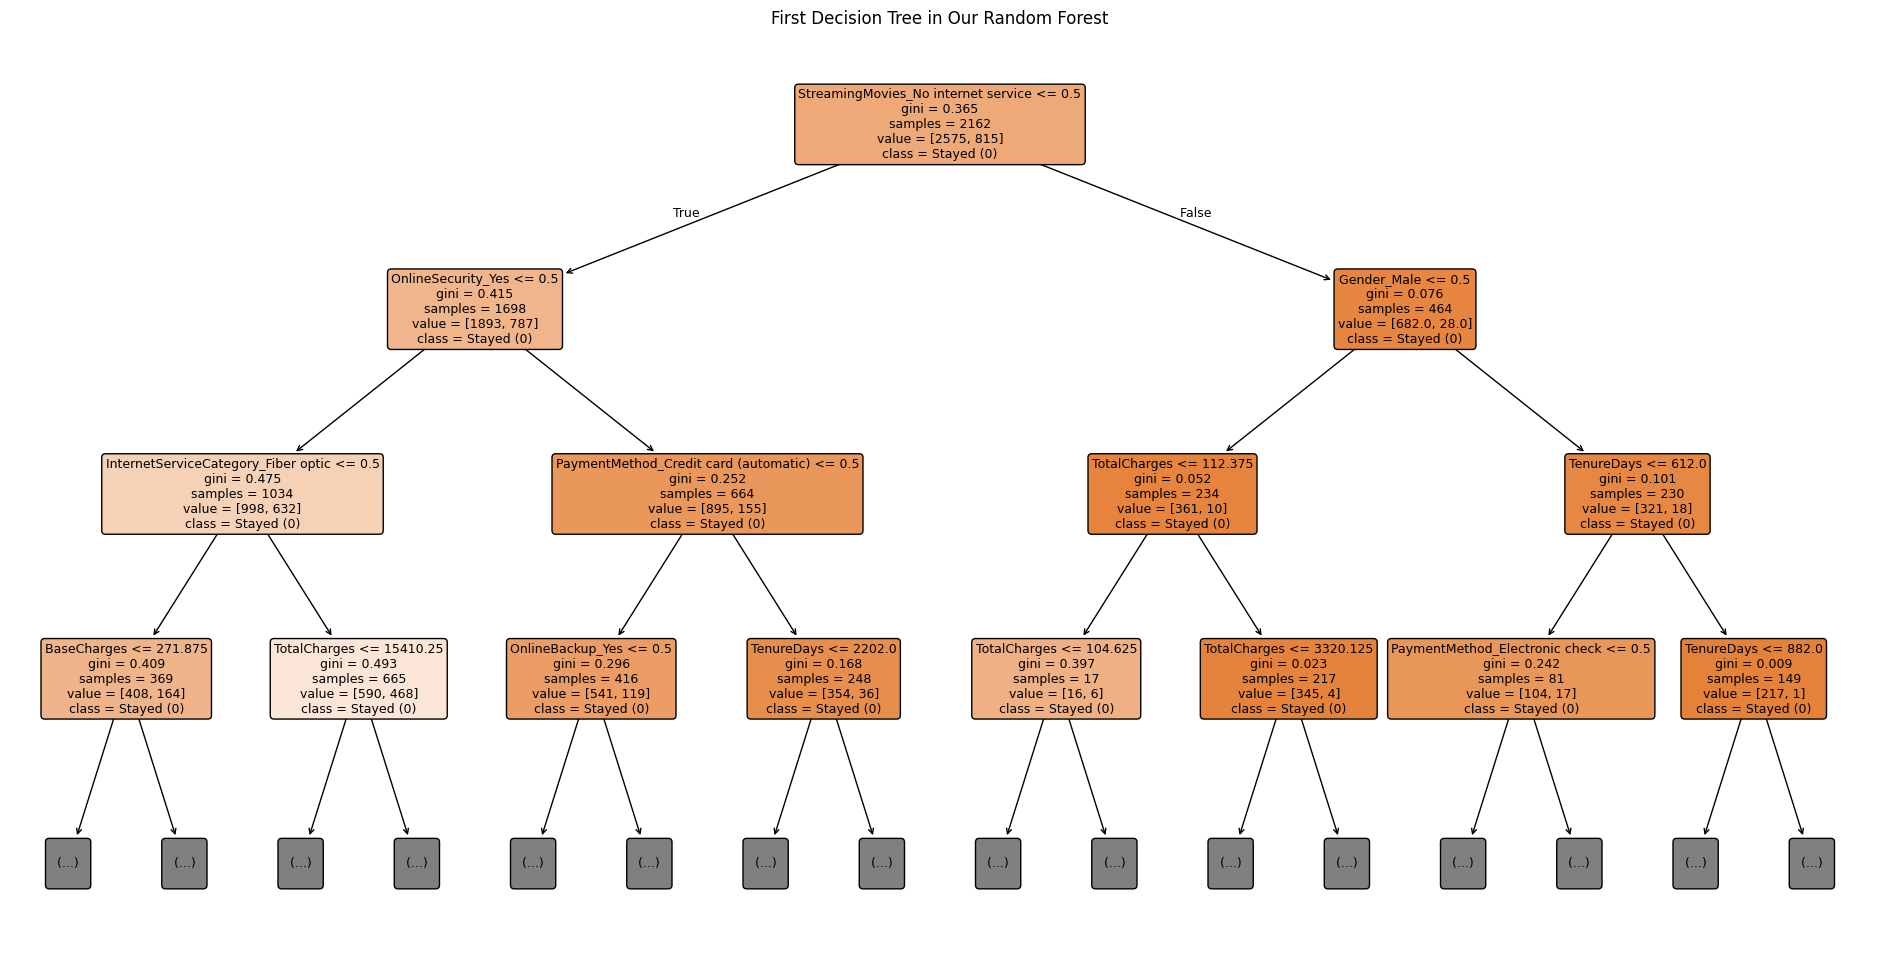

In [ ]:
#I want to see the visual tree
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Select the first tree from the Random Forest
first_tree = rf_model.estimators_[0]

# Set the size of the graph
plt.figure(figsize=(24, 12))

# Draw the tree
plot_tree(
    first_tree,
    feature_names=X_train.columns,
    class_names=['Stayed (0)', 'Churned (1)'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("First Decision Tree in Our Random Forest")
plt.show()


Getting the submission file ready.

In [ ]:
# 1. Re-fit the model on 100% of training data for optimal performance
rf_full = RandomForestClassifier(n_estimators=100, random_state=42)
rf_full.fit(X_encoded, y)

# 2. Predict on the test set
test_preds = rf_full.predict(X_test_encoded)

# 3. Populate submission dataframe and export CSV
submission['Churn'] = test_preds
submission.to_csv('submission.csv', index=False)

In [40]:
# Save submission CSV to Google Drive
submission.to_csv(f'{output_dir}/submission.csv', index=False)

print(f"File successfully saved to Google Drive: {output_dir}/submission.csv")

File successfully saved to Google Drive: /content/drive/MyDrive/Kaggle/submission.csv
